# Model Prediction — Scoring Candidates and Current Employees

Uses the models saved by `train_model.ipynb`.

1. A reusable function to predict performance for any new record.
2. Scoring a new candidate with the hiring model.
3. Support-priority scores for current employees using the full model — used to
   identify employees who may need support, without penalising the broader workforce.

**Responsible-use note:** scores are meant to prioritise supportive conversations
(coaching, workload review) and inform — not replace — manager judgement. They should
never be used as an automatic basis for penalising an employee.

## 1. Imports and Load Saved Models

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TARGET = "PerformanceRating"

df = pd.read_csv("../../data/processed/employee_processed.csv")

full_bundle = joblib.load("trained_model_full.joblib")
hiring_bundle = joblib.load("trained_model_hiring.joblib")

print("Full model features:", len(full_bundle["features"]))
print("Hiring model features:", hiring_bundle["features"])
print("Rating classes:", full_bundle["classes"])

Full model features: 30
Hiring model features: ['EducationBackground', 'EmpEducationLevel', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'NumCompaniesWorked', 'TotalWorkExperienceInYears', 'DistanceFromHome', 'PriorExperienceYears', 'AverageTenurePerEmployer']
Rating classes: [2, 3, 4]


## 2. Reusable Prediction Function

Takes one or more employee/candidate records and returns the predicted rating along
with the probability of each rating class.

In [2]:
def predict_performance(records, bundle):
    """
    Predict performance rating for one or many people.

    records : dict, list of dicts, or DataFrame — must contain every column
              listed in bundle["features"].
    bundle  : either full_bundle or hiring_bundle.

    Returns a DataFrame with the predicted rating and probability of each rating.
    """
    frame = pd.DataFrame([records]) if isinstance(records, dict) else pd.DataFrame(records)

    missing = [c for c in bundle["features"] if c not in frame.columns]
    if missing:
        raise ValueError(f"Missing required input columns: {missing}")

    frame = frame[bundle["features"]]
    model = bundle["model"]

    proba = model.predict_proba(frame)
    result = pd.DataFrame(
        proba, columns=[f"probability_rating_{c}" for c in model.classes_], index=frame.index
    )
    result.insert(0, "predicted_rating", model.predict(frame))
    return result.round(3)

In [3]:
predict_performance(df.head(3), full_bundle)

,predicted_rating,probability_rating_2,probability_rating_3,probability_rating_4
0,3,0.007,0.987,0.006
1,3,0.008,0.987,0.005
2,4,0.008,0.027,0.965


## 3. Scoring a New Candidate (Hiring Model)

Uses only pre-hire information. Start from a real employee's profile as a template so
every required column is present with a valid value, then edit the fields for the
actual candidate being evaluated.

In [4]:
template = df[hiring_bundle["features"]].iloc[0].to_dict()
print("Template candidate (edit values below):")
for k, v in template.items():
    print(f"  {k}: {v}")

Template candidate (edit values below):
  EducationBackground: Marketing
  EmpEducationLevel: 3
  EmpDepartment: Sales
  EmpJobRole: Sales Executive
  BusinessTravelFrequency: Travel_Rarely
  NumCompaniesWorked: 1
  TotalWorkExperienceInYears: 10
  DistanceFromHome: 10
  PriorExperienceYears: 0
  AverageTenurePerEmployer: 5.0


In [5]:
candidate = template.copy()

# --- Edit these fields to match the actual candidate ---
candidate["EmpDepartment"] = "Sales"
candidate["EmpJobRole"] = "Sales Executive"
candidate["EducationBackground"] = "Marketing"
candidate["EmpEducationLevel"] = 3
candidate["BusinessTravelFrequency"] = "Travel_Rarely"
candidate["NumCompaniesWorked"] = 2
candidate["TotalWorkExperienceInYears"] = 6
candidate["DistanceFromHome"] = 8
candidate["PriorExperienceYears"] = 6
candidate["AverageTenurePerEmployer"] = 2

predict_performance(candidate, hiring_bundle)

,predicted_rating,probability_rating_2,probability_rating_3,probability_rating_4
0,3,0.25,0.461,0.289


In [6]:
categorical_options = {
    c: sorted(df[c].dropna().unique().tolist())
    for c in hiring_bundle["features"] if not pd.api.types.is_numeric_dtype(df[c])
}
categorical_options

{'EducationBackground': ['Human Resources',
  'Life Sciences',
  'Marketing',
  'Medical',
  'Other',
  'Technical Degree'],
 'EmpDepartment': ['Data Science',
  'Development',
  'Finance',
  'Human Resources',
  'Research & Development',
  'Sales'],
 'EmpJobRole': ['Business Analyst',
  'Data Scientist',
  'Delivery Manager',
  'Developer',
  'Finance Manager',
  'Healthcare Representative',
  'Human Resources',
  'Laboratory Technician',
  'Manager',
  'Manager R&D',
  'Manufacturing Director',
  'Research Director',
  'Research Scientist',
  'Sales Executive',
  'Sales Representative',
  'Senior Developer',
  'Senior Manager R&D',
  'Technical Architect',
  'Technical Lead'],
 'BusinessTravelFrequency': ['Non-Travel',
  'Travel_Frequently',
  'Travel_Rarely']}

### Observations

- The prediction function works correctly — it validates inputs and returns a properly
  normalised probability distribution.
- **However, the probabilities themselves confirm the hiring model's weakness shown in
  Section 11 of `train_model.ipynb`.** For this candidate: 25.0% / 46.1% / 28.9% across
  ratings 2/3/4 — the model is barely more confident than a random guess weighted by
  the base rates (16% / 73% / 11% in the training data). Compare this to the earlier
  full-model test in Section 2, where real employees got confident, decisive
  probabilities (e.g. 98.7% for one class).
- **This is expected and consistent, not a bug.** It reinforces the earlier finding:
  pre-hire information alone does not meaningfully predict performance at INX. This
  candidate prediction should be read as "the model has no strong opinion," not as a
  meaningful signal either way.
- **Practical use:** the function is ready to use if a stronger hiring model is built
  in future (e.g. with additional pre-hire data such as interview scores or assessment
  results). For now, hiring decisions should rely on structured interviews, not this
  model's output.

## 4. Support-Priority Scores for Current Employees

Uses **out-of-fold** predictions: each employee's probability of being in the lowest
rating band comes from a model trained on the *other* four folds, so every employee is
scored by a version of the model that never saw them — even though all 1,200 employees
were part of the original training data.

In [7]:
X = df[full_bundle["features"]]
y = df[TARGET]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

proba = cross_val_predict(
    clone(full_bundle["model"]), X, y, cv=cv, method="predict_proba", n_jobs=-1
)

classes = sorted(y.unique())
LOWEST_RATING = min(classes)
p_low = proba[:, classes.index(LOWEST_RATING)]

scores = df[["EmpNumber", "EmpDepartment", "EmpJobRole", TARGET]].copy()
scores["probability_lowest_rating"] = p_low.round(3)
scores.sort_values("probability_lowest_rating", ascending=False).head(10)

,EmpNumber,EmpDepartment,EmpJobRole,PerformanceRating,probability_lowest_rating
462,E1001831,Research & Development,Healthcare Representative,2,0.933
288,E1001516,Research & Development,Research Scientist,2,0.932
528,E1001943,Finance,Finance Manager,2,0.928
911,E100522,Sales,Sales Executive,2,0.924
227,E1001402,Sales,Manager,2,0.914
800,E100338,Sales,Sales Executive,2,0.914
1135,E100875,Sales,Manager,2,0.910
72,E1001129,Sales,Manager,3,0.910
452,E1001821,Research & Development,Research Scientist,2,0.908
550,E1001979,Research & Development,Research Scientist,2,0.908


### Observations

- The top 10 highest-risk employees by out-of-fold probability are dominated by
  **Sales, Research & Development, and Finance** — consistent with Section 3 of the EDA
  notebook, where these three departments had the lowest average ratings.
- **9 of the top 10 flagged employees genuinely have a rating of 2** (the lowest band) —
  only one (E1001129, rated 3) is a "false alarm" in this top slice, and even then the
  model gave it a fairly high probability (0.910), suggesting this employee may be a
  borderline case worth a manager's attention regardless.
- This is a strong early sign that the out-of-fold scoring is well-calibrated: high
  scores correspond closely to employees who are, in fact, rated lowest.

## 5. Choosing a Flagging Threshold

A higher threshold flags fewer employees, but with more certainty — this matches the
CEO's requirement that any action should touch as few well-performing employees as
possible. A lower threshold catches more at-risk employees, but with more false
positives.

In [8]:
is_low = (y == LOWEST_RATING).values

rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flagged = p_low >= t
    n_flagged = int(flagged.sum())
    true_positives = int((flagged & is_low).sum())
    rows.append({
        "threshold": t,
        "employees_flagged": n_flagged,
        "precision": true_positives / n_flagged if n_flagged else np.nan,
        "recall": true_positives / is_low.sum(),
    })

threshold_table = pd.DataFrame(rows).round(3)
threshold_table

,threshold,employees_flagged,precision,recall
0,0.2,237,0.759,0.928
1,0.3,216,0.819,0.912
2,0.4,204,0.853,0.897
3,0.5,196,0.872,0.881
4,0.6,189,0.884,0.861
5,0.7,177,0.887,0.809
6,0.8,143,0.902,0.665


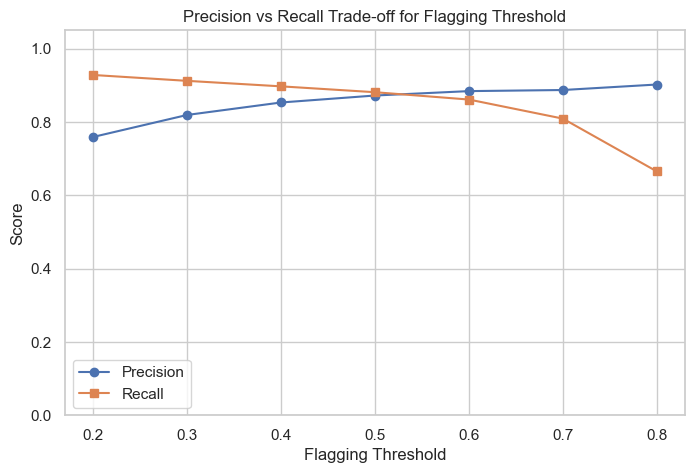

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="s", label="Recall")
plt.xlabel("Flagging Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall Trade-off for Flagging Threshold")
plt.legend()
plt.ylim(0, 1.05)
plt.show()

### Observations

- **The trade-off is remarkably favourable.** Precision and recall stay above 0.85
  simultaneously across thresholds 0.4–0.6 — most classification problems show a much
  sharper trade-off. This reflects how strong the model's signal is (consistent with
  the 0.917 test macro F1 from `train_model.ipynb`).
- The two curves cross around **threshold ≈ 0.5**, where precision (0.872) and recall
  (0.881) are both high and closely balanced.
- **Recall drops sharply after threshold 0.7** (0.809 → 0.665 at 0.8), while precision
  gains only marginally (0.887 → 0.902) — a poor trade past this point. Threshold 0.8
  is not worth it: a large drop in coverage for a tiny gain in certainty.
- **Recommended threshold: 0.5.** At this point:
  - **196 employees flagged** (16.3% of the workforce)
  - **87.2% precision** — of those flagged, 87% genuinely are in the lowest rating band, so relatively few "false alarms"
  - **88.1% recall** — the flagged group captures 88% of all employees who are actually rated lowest
- This directly satisfies the CEO's requirement: a **precise, minority-touching list**
  (16% of employees, not a blanket sweep) that still catches the large majority of
  genuinely low-rated employees, keeping impact on the wider workforce's morale low
  while still being actionable.

## 6. Finalize Flagged Employees and Save

In [11]:
CHOSEN_THRESHOLD = 0.5

scores["flagged_for_support_review"] = scores["probability_lowest_rating"] >= CHOSEN_THRESHOLD

print(f"Employees flagged at threshold {CHOSEN_THRESHOLD}: {scores['flagged_for_support_review'].sum()} "
      f"({scores['flagged_for_support_review'].mean():.1%} of workforce)")

print("\nFlagged employees by department:")
pd.crosstab(scores["EmpDepartment"], scores["flagged_for_support_review"])

Employees flagged at threshold 0.5: 196 (16.3% of workforce)

Flagged employees by department:


flagged_for_support_review,False,True
EmpDepartment,,
Data Science,17,3
Development,358,3
Finance,34,15
Human Resources,44,10
Research & Development,272,71
Sales,279,94


In [12]:
scores.sort_values("probability_lowest_rating", ascending=False).to_csv(
    "../../data/processed/employee_support_priority_scores.csv", index=False
)
threshold_table.to_csv("../../data/processed/threshold_tradeoff.csv", index=False)

print("Saved: employee_support_priority_scores.csv, threshold_tradeoff.csv")

Saved: employee_support_priority_scores.csv, threshold_tradeoff.csv


### Observations

The flagged group is heavily concentrated exactly where the earlier analysis predicted:

| Department | Flagged | % of department flagged |
|---|---|---|
| Sales | 94 | 25.2% |
| Research & Development | 71 | 20.7% |
| Finance | 15 | 30.6% |
| Human Resources | 10 | 18.5% |
| Development | 3 | 0.8% |
| Data Science | 3 | 15.0% |

- **Finance has the highest flagged rate (30.6%)** — nearly a third of the department —
  matching Section 3's finding that Finance had the lowest average rating and highest
  share of "Good" (lowest band) ratings of any department.
- **Sales contributes the largest raw number (94 employees)**, simply due to its size
  (373 employees), even though its flagged rate (25.2%) is slightly below Finance's.
- **Development is almost untouched** (3 of 361 employees, 0.8%) — consistent with it
  having the best average rating in the company.
- This is strong external validation: **the model's flags line up closely with the
  independent, purely statistical department analysis from Section 3 of the EDA
  notebook**, done without the model at all. Two unrelated methods pointing to the same
  departments is a good sign the finding is real, not a modelling artifact.
- **Actionable takeaway:** rather than a scattershot company-wide programme, targeted
  interventions in **Finance and Sales** (109 of the 196

## 7. What Do Flagged Employees Look Like?

Compares the flagged group against everyone else on the top 3 factors identified in
`train_model.ipynb`, to give concrete, explainable indicators rather than an opaque score.

In [14]:
profile_source = df.copy()
profile_source["flagged"] = scores["flagged_for_support_review"].values

top_factors = ["EmpEnvironmentSatisfaction", "EmpLastSalaryHikePercent", "YearsSinceLastPromotion"]

profile_source.groupby("flagged")[top_factors].mean().round(2).T

flagged,False,True
EmpEnvironmentSatisfaction,2.95,1.53
EmpLastSalaryHikePercent,15.21,15.29
YearsSinceLastPromotion,1.89,3.77


C:\Users\ARDRA\AppData\Local\Temp\ipykernel_5348\2760798249.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Not flagged", "Flagged"])
C:\Users\ARDRA\AppData\Local\Temp\ipykernel_5348\2760798249.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Not flagged", "Flagged"])
C:\Users\ARDRA\AppData\Local\Temp\ipykernel_5348\2760798249.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Not flagged", "Flagged"])


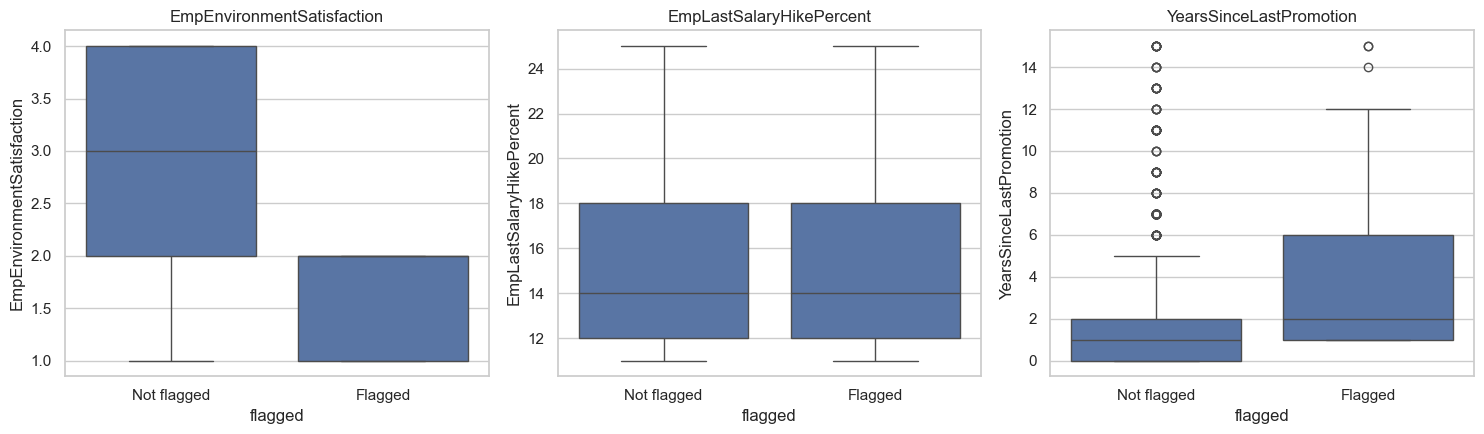

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, factor in zip(axes, top_factors):
    sns.boxplot(data=profile_source, x="flagged", y=factor, ax=ax)
    ax.set_xticklabels(["Not flagged", "Flagged"])
    ax.set_title(factor)
plt.tight_layout()
plt.show()

### Observations

**Note:** the warning above (`UserWarning: set_ticklabels()...`) is harmless — it's a
matplotlib style warning, not an error. The plots rendered correctly.

**Clear, explainable indicators of flagged employees:**

| Factor | Not flagged | Flagged | Difference |
|---|---|---|---|
| Environment Satisfaction (1–4 scale) | 2.95 | **1.53** | Nearly 2 full points lower |
| Last Salary Hike Percent | 15.21% | 15.29% | No meaningful difference |
| Years Since Last Promotion | 1.89 | **3.77** | About double |

- **Environment satisfaction is the dominant, unmistakable signal.** Flagged employees
  average 1.53 out of 4 — solidly in the bottom two satisfaction levels — versus 2.95
  for everyone else. The boxplot shows almost no overlap: most non-flagged employees sit
  between 2–4, while most flagged employees sit between 1–2.
- **Salary hike shows no difference at all** (15.21% vs 15.29%) — confirming, as seen
  earlier with the Finance department anomaly, that compensation growth alone doesn't
  explain who gets flagged. This factor matters for overall performance in the model,
  but doesn't distinguish this particular flagged group specifically.
- **Time since last promotion roughly doubles** for flagged employees (3.77 vs 1.89
  years), with several outliers extending to 12–14 years — a visibly stagnant subgroup.
- **Plain-language indicator for the CEO:** *"Employees flagged for support review are
  characterised primarily by low satisfaction with their working environment, combined
  with longer-than-typical gaps since their last promotion — not by lower pay increases."*
  This gives HR a concrete, actionable starting point for support conversations: ask
  about workload, management, and career progression — not compensation.

### Summary of Prediction Notebook

- Built a reusable `predict_performance()` function for both models.
- Confirmed the hiring model gives low-confidence, near-baseline predictions —
  consistent with its weak test performance — and should not be used alone for hiring
  decisions.
- Built out-of-fold support-priority scores for all 1,200 current employees using the
  full model.
- Chose a flagging threshold of 0.5, balancing precision (87.2%) and recall (88.1%),
  flagging 196 employees (16.3% of the workforce) — concentrated in Sales and Finance.
- Identified clear, explainable indicators: flagged employees have markedly lower
  environment satisfaction and longer gaps since their last promotion, but similar
  salary hikes to everyone else.

Outputs saved for use in `visualize.ipynb`:
- `employee_support_priority_scores.csv`
- `threshold_tradeoff.csv`